<a href="https://colab.research.google.com/github/xXBl4ckXentxX/Deep-Learning/blob/main/Hands_on_3_MLP_Iris.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Hands-on 3 — Clasificación de flores Iris con una red neuronal MLP

**Objetivo:** aprender a utilizar una red neuronal **Perceptrón Multicapa (MLP)** para reconocer tres especies de flores a partir de cuatro medidas. Usaremos `scikit-learn`, una biblioteca que ya incluye la red neuronal.

**Al terminar podrás:**
1. Explicar qué son las entradas, los pesos, las capas y la función de activación.
2. Explorar y graficar el conjunto de datos Iris.
3. Dividir y estandarizar correctamente los datos.
4. Entrenar una red neuronal y comparar arquitecturas.
5. Evaluar el modelo y predecir la especie de una flor nueva.
6. Comprobar cómo se calculan las salidas de la red usando sus pesos.

**Cómo usar el notebook:** ejecuta las celdas **de arriba hacia abajo** (en Google Colab: *Entorno de ejecución → Ejecutar todas*). No necesitas descargar archivos ni instalar paquetes adicionales en Colab.

> **Importante:** este Hands-on usa `scikit-learn` para entrenar. En el Hands-on 4 programaremos nosotros mismos los cálculos de la red neuronal.

## 1. Conceptos básicos de una red neuronal

Una **neurona artificial** recibe valores, los multiplica por **pesos**, les suma un **sesgo** y aplica una **función de activación**.

\[
z = x_1w_1+x_2w_2+\dots+x_nw_n+b, \qquad a=f(z)
\]

| Elemento | Explicación sencilla | Ejemplo con Iris |
|---|---|---|
| Entrada (`x`) | Información que recibe la red | Largo y ancho de sépalos y pétalos |
| Peso (`w`) | Importancia que la red aprende para cada dato | Una medida puede influir más que otra |
| Sesgo (`b`) | Ajuste adicional que aprende la red | Permite desplazar el resultado |
| Activación (`f`) | Transforma la suma para que la red aprenda relaciones complejas | ReLU |
| Salida | Respuesta final de la red | Probabilidad de cada especie |

### ¿Qué significa MLP?
Un **Perceptrón Multicapa** conecta muchas neuronas organizadas en:
- **Capa de entrada:** en Iris recibe 4 características.
- **Capas ocultas:** transforman los datos y aprenden patrones.
- **Capa de salida:** calcula 3 probabilidades, una por especie.

Una red **4 → 10 → 10 → 3** tiene 4 entradas, 2 capas ocultas de 10 neuronas cada una y 3 salidas.

### 1.1 Funciones de activación

Las activaciones más conocidas son **escalón**, **lineal**, **sigmoide**, **tanh** y **ReLU**. La más usada en las capas ocultas de esta práctica será **ReLU**, porque conserva los números positivos y convierte los negativos en 0.

La siguiente celda **solo dibuja funciones matemáticas**. Todavía no entrena la red.

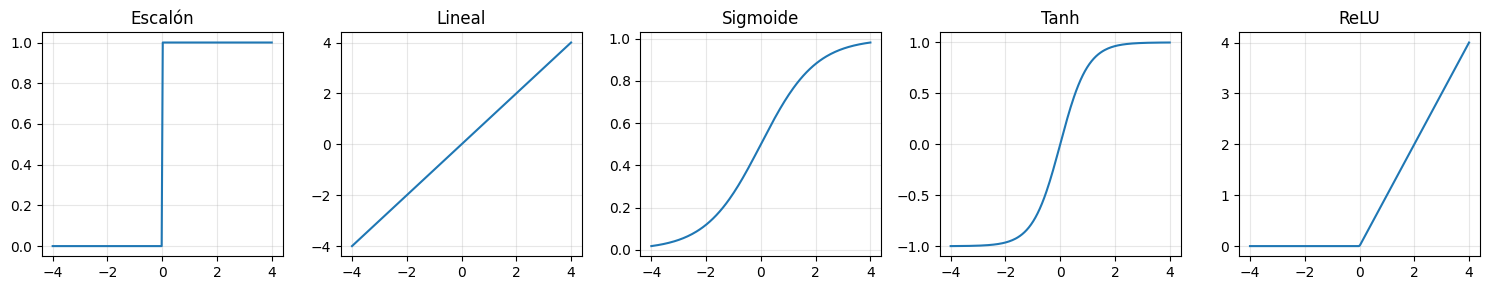

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Valores que usaremos para dibujar las funciones.
z = np.linspace(-4, 4, 200)
funciones = {
    "Escalón": (z >= 0).astype(int),
    "Lineal": z,
    "Sigmoide": 1 / (1 + np.exp(-z)),
    "Tanh": np.tanh(z),
    "ReLU": np.maximum(0, z),
}

fig, ejes = plt.subplots(1, 5, figsize=(15, 3))
for eje, (nombre, resultado) in zip(ejes, funciones.items()):
    eje.plot(z, resultado)
    eje.set_title(nombre)
    eje.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### 1.2 ¿Cómo aprende una red neuronal?

El entrenamiento repite cuatro operaciones:
1. **Forward pass:** los datos pasan por las capas y generan una predicción.
2. **Pérdida:** medimos qué tan diferente es la predicción de la respuesta correcta.
3. **Backpropagation:** calculamos cuánto contribuyó cada peso al error.
4. **Actualización:** modificamos los pesos para intentar reducirlo.

Una **época** es una vuelta completa por los datos de entrenamiento. `MLPClassifier.fit()` realiza automáticamente estos cálculos.

**Modelo matemático en pocas palabras:** cada capa calcula `entrada @ pesos + sesgos`, luego aplica una activación. En la última capa, `softmax` convierte los valores en probabilidades que suman 1. En entrenamiento, la **entropía cruzada** mide el error y el **descenso del gradiente** permite ajustar los pesos:

\[
W_{nuevo}=W_{actual}-\eta\frac{\partial L}{\partial W}
\]

Aquí `L` es la pérdida y `η` (eta) es la **tasa de aprendizaje**. Cuanto mayor sea, más grandes serán los cambios de los pesos.

## 2. Dataset Iris: conocer los datos

Iris tiene **150 flores** de 3 especies: **setosa**, **versicolor** y **virginica**. Cada flor se describe con 4 medidas en centímetros.

- `sepal_length`: largo del sépalo.
- `sepal_width`: ancho del sépalo.
- `petal_length`: largo del pétalo.
- `petal_width`: ancho del pétalo.

**Objetivo de clasificación:** recibir las cuatro medidas y decidir a qué especie corresponde la flor.

In [ ]:
from sklearn.datasets import load_iris

iris = load_iris()
columnas = ["sepal_length", "sepal_width", "petal_length", "petal_width"]

# Creamos una tabla para examinar los datos.
df = pd.DataFrame(iris.data, columns=columnas)
df["species"] = iris.target_names[iris.target]

print("Tamaño de la tabla (filas, columnas):", df.shape)
print("\nPrimeras cinco flores:")
print(df.head().to_string(index=False))

Tamaño de la tabla (filas, columnas): (150, 5)

Primeras cinco flores:
 sepal_length  sepal_width  petal_length  petal_width species
          5.1          3.5           1.4          0.2  setosa
          4.9          3.0           1.4          0.2  setosa
          4.7          3.2           1.3          0.2  setosa
          4.6          3.1           1.5          0.2  setosa
          5.0          3.6           1.4          0.2  setosa


**Qué significa el resultado:** hay 150 filas (flores) y 5 columnas (4 medidas y la especie). La columna `species` será nuestra **respuesta correcta**.

Antes de entrenar, comprobamos que no falten datos y cuántas flores existen de cada especie.

In [ ]:
print("Cantidad de flores por especie:")
print(df["species"].value_counts())

print("\nDatos faltantes por columna:")
print(df.isnull().sum())

print("\nResumen estadístico de las medidas:")
print(df[columnas].describe().round(2))

Cantidad de flores por especie:
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64

Datos faltantes por columna:
sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64

Resumen estadístico de las medidas:
       sepal_length  sepal_width  petal_length  petal_width
count        150.00       150.00        150.00       150.00
mean           5.84         3.06          3.76         1.20
std            0.83         0.44          1.77         0.76
min            4.30         2.00          1.00         0.10
25%            5.10         2.80          1.60         0.30
50%            5.80         3.00          4.35         1.30
75%            6.40         3.30          5.10         1.80
max            7.90         4.40          6.90         2.50


### 2.1 Separar las entradas (X) y las respuestas (y)

- `X` contiene las **4 medidas** que la red recibirá.
- `y` contiene la **especie** que debe aprender a identificar.

Usamos `.iloc` para elegir columnas por posición; las posiciones comienzan en 0.

In [ ]:
X = df.iloc[:, 0:4]   # Todas las filas; primeras 4 columnas.
y = df.iloc[:, 4]     # Todas las filas; última columna.

print("Dimensiones de X:", X.shape)
print("Dimensiones de y:", y.shape)
print("Primera especie:", y.iloc[0])

Dimensiones de X: (150, 4)
Dimensiones de y: (150,)
Primera especie: setosa


### 2.2 Dibujar las flores con gráficas de dispersión

Cada punto representa una flor. El color señala su especie. Las gráficas muestran por qué algunas especies se reconocen con mayor facilidad que otras.

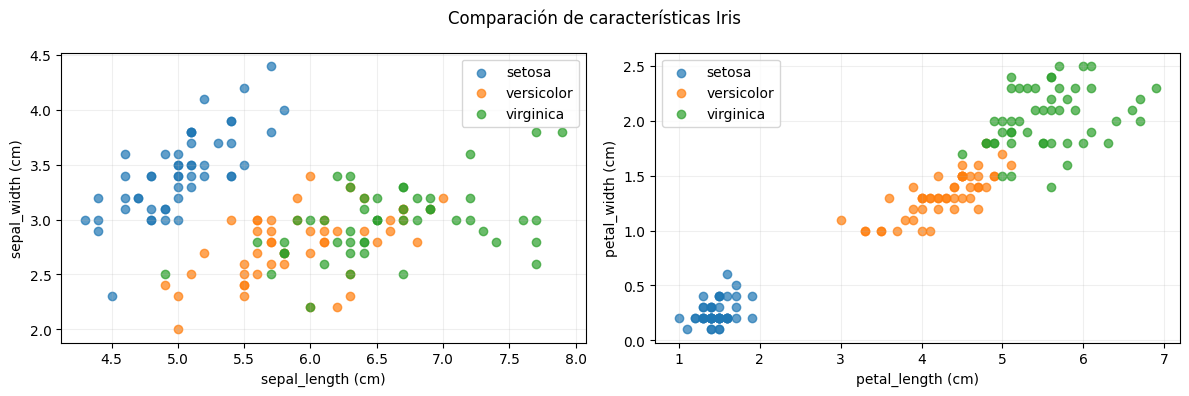

In [ ]:
pares = [("sepal_length", "sepal_width"),
         ("petal_length", "petal_width")]

fig, ejes = plt.subplots(1, 2, figsize=(12, 4))
for eje, (medida_x, medida_y) in zip(ejes, pares):
    for especie in iris.target_names:
        flores = df[df["species"] == especie]
        eje.scatter(flores[medida_x], flores[medida_y], label=especie, alpha=0.7)
    eje.set_xlabel(medida_x + " (cm)")
    eje.set_ylabel(medida_y + " (cm)")
    eje.legend()
    eje.grid(alpha=0.2)

plt.suptitle("Comparación de características Iris")
plt.tight_layout()
plt.show()

**Interpretación:** `setosa` suele distinguirse claramente por sus pétalos. `versicolor` y `virginica` pueden aparecer más cerca, lo que dificulta clasificarlas.

## 3. Preparar los datos

### 3.1 Dividir en entrenamiento y prueba

Reservamos **80 % (120 flores)** para que la red aprenda y **20 % (30 flores)** para comprobar su desempeño al final. `stratify=y` conserva la proporción de especies en ambos grupos.

In [ ]:
from sklearn.model_selection import train_test_split

SEMILLA = 42
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEMILLA, stratify=y
)

print("Flores de entrenamiento:", len(X_train))
print("Flores de prueba:", len(X_test))
print("Especies en prueba:")
print(y_test.value_counts())

Flores de entrenamiento: 120
Flores de prueba: 30
Especies en prueba:
species
setosa        10
virginica     10
versicolor    10
Name: count, dtype: int64


### 3.2 Estandarizar las cuatro medidas

Los valores de entrada deben estar en escalas comparables. `StandardScaler` transforma cada columna mediante:

\[
x_{escalado}=\frac{x-\text{media}}{\text{desviación estándar}}
\]

**Regla importante:** calculamos la media y desviación **solo con entrenamiento** (`fit_transform`). En los datos de prueba usamos `transform`, para no revelar a la red información que todavía no debería conocer.

In [ ]:
from sklearn.preprocessing import StandardScaler

escalador = StandardScaler()
X_train_esc = escalador.fit_transform(X_train)
X_test_esc = escalador.transform(X_test)

print("Media antes de escalar:", X_train.mean().round(2).to_list())
print("Media después de escalar:", X_train_esc.mean(axis=0).round(2))
print("Desviación después de escalar:", X_train_esc.std(axis=0).round(2))

Media antes de escalar: [5.84, 3.05, 3.77, 1.2]
Media después de escalar: [-0. -0.  0.  0.]
Desviación después de escalar: [1. 1. 1. 1.]


## 4. Elegir y entrenar la red neuronal

`MLPClassifier` de `scikit-learn` realiza los cálculos de propagación, error y ajuste de pesos. Sus parámetros principales son:

| Parámetro | Qué controla |
|---|---|
| `hidden_layer_sizes=(10, 10)` | Dos capas ocultas de 10 neuronas cada una |
| `activation='relu'` | Función de activación en las capas ocultas |
| `max_iter=1500` | Cantidad máxima de épocas |
| `random_state=42` | Permite repetir el experimento |

### 4.1 Comparar arquitecturas con validación cruzada

Probaremos varias cantidades de neuronas. En la **validación cruzada** se divide **solo el entrenamiento** en partes: algunas sirven para entrenar y otra para validar. Repetimos el proceso con cinco partes y obtenemos el promedio de *accuracy*.

Usamos un `pipeline` para que el escalado ocurra correctamente dentro de cada división de validación.

In [ ]:
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import make_pipeline

arquitecturas = [(5,), (10,), (10, 10), (20, 10)]
resultados = []

for capas in arquitecturas:
    candidato = make_pipeline(
        StandardScaler(),
        MLPClassifier(hidden_layer_sizes=capas, max_iter=1500, random_state=SEMILLA)
    )
    puntajes = cross_val_score(candidato, X_train, y_train, cv=5, scoring="accuracy")
    resultados.append({"capas": capas, "accuracy_promedio": puntajes.mean()})

tabla_modelos = pd.DataFrame(resultados).sort_values("accuracy_promedio", ascending=False)
print(tabla_modelos.to_string(index=False))

   capas  accuracy_promedio
    (5,)           0.966667
   (10,)           0.958333
(10, 10)           0.958333
(20, 10)           0.958333


**Cómo leer la tabla:** una exactitud de `0.95` significa que el modelo acertó aproximadamente el **95 %** en las particiones de validación. La tabla ayuda a seleccionar una arquitectura **sin tocar las 30 flores de prueba**.

### 4.2 Entrenar el modelo final

Elegimos la arquitectura con mayor exactitud media y entrenamos usando las **120 flores de entrenamiento**.

In [ ]:
capas_elegidas = tabla_modelos.iloc[0]["capas"]

modelo = MLPClassifier(
    hidden_layer_sizes=capas_elegidas,
    activation="relu",
    max_iter=1500,
    random_state=SEMILLA
)

modelo.fit(X_train_esc, y_train)
print("Arquitectura elegida:", capas_elegidas)
print("Épocas utilizadas:", modelo.n_iter_)
print("Pérdida final:", round(modelo.loss_, 4))

Arquitectura elegida: (5,)
Épocas utilizadas: 1161
Pérdida final: 0.108


### 4.3 Observar los pesos y la pérdida

- `coefs_` son los **pesos** que la red aprendió.
- `intercepts_` son los **sesgos**.
- `loss_curve_` muestra cómo cambió el error durante el entrenamiento.

Si la curva de pérdida disminuye, normalmente la red está aprendiendo.

Capa 1: pesos (4, 5), sesgos (5,)
Capa 2: pesos (5, 3), sesgos (3,)


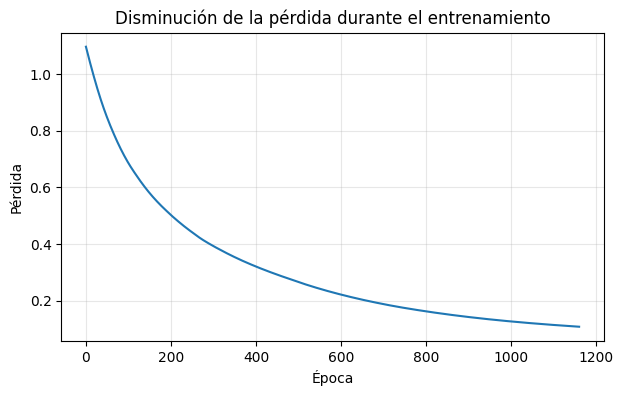

In [ ]:
for numero, (pesos, sesgos) in enumerate(zip(modelo.coefs_, modelo.intercepts_), start=1):
    print(f"Capa {numero}: pesos {pesos.shape}, sesgos {sesgos.shape}")

plt.figure(figsize=(7, 4))
plt.plot(modelo.loss_curve_)
plt.title("Disminución de la pérdida durante el entrenamiento")
plt.xlabel("Época")
plt.ylabel("Pérdida")
plt.grid(alpha=0.3)
plt.show()

### 4.4 Ver una frontera de decisión (con solo 2 características)

Para dibujar las regiones que la red reconoce, creamos **otro modelo únicamente para la gráfica**, usando el largo y ancho del pétalo. El modelo principal continúa usando las 4 medidas.

El **fondo** muestra la especie que predeciría la red; los **puntos** corresponden a flores de prueba.

/opt/pyvenv/lib/python3.13/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1500) reached and the optimization hasn't converged yet.
  warnings.warn(


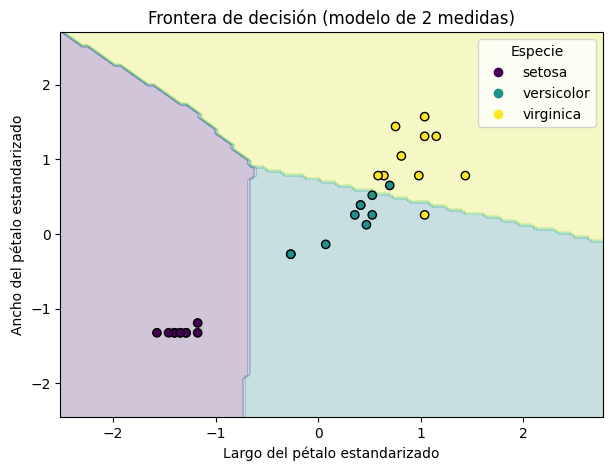

In [ ]:
from sklearn.inspection import DecisionBoundaryDisplay

columnas_2d = ["petal_length", "petal_width"]
X_2d_train = X_train[columnas_2d]
X_2d_test = X_test[columnas_2d]

escalador_2d = StandardScaler()
X_2d_train_esc = escalador_2d.fit_transform(X_2d_train)
X_2d_test_esc = escalador_2d.transform(X_2d_test)

# Convertimos los nombres de especie a 0, 1 y 2 para graficar.
y_2d_train = np.searchsorted(iris.target_names, y_train)
y_2d_test = np.searchsorted(iris.target_names, y_test)

modelo_2d = MLPClassifier(hidden_layer_sizes=capas_elegidas, max_iter=1500, random_state=SEMILLA)
modelo_2d.fit(X_2d_train_esc, y_2d_train)

fig, eje = plt.subplots(figsize=(7, 5))
DecisionBoundaryDisplay.from_estimator(
    modelo_2d, X_2d_train_esc, response_method="predict", alpha=0.25, ax=eje
)
puntos = eje.scatter(X_2d_test_esc[:, 0], X_2d_test_esc[:, 1], c=y_2d_test, edgecolors="k")
eje.legend(puntos.legend_elements()[0], iris.target_names, title="Especie")
eje.set_xlabel("Largo del pétalo estandarizado")
eje.set_ylabel("Ancho del pétalo estandarizado")
eje.set_title("Frontera de decisión (modelo de 2 medidas)")
plt.show()

## 5. Evaluar la red con datos nuevos

Ahora usamos las 30 flores reservadas. **Accuracy** o *exactitud* es la proporción de predicciones correctas:

\[
Accuracy=\frac{\text{aciertos}}{\text{total de muestras}}
\]

Comparamos entrenamiento contra prueba: si el porcentaje en entrenamiento es mucho mayor que el de prueba, podría existir **sobreajuste**.

In [ ]:
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay, classification_report

predicciones = modelo.predict(X_test_esc)
acc_entrenamiento = accuracy_score(y_train, modelo.predict(X_train_esc))
acc_prueba = accuracy_score(y_test, predicciones)

print(f"Exactitud en entrenamiento: {acc_entrenamiento:.2%}")
print(f"Exactitud en prueba:        {acc_prueba:.2%}")

Exactitud en entrenamiento: 98.33%
Exactitud en prueba:        96.67%


### 5.1 Matriz de confusión y reporte

En una **matriz de confusión**, cada fila es la especie real y cada columna es la predicha. Los valores de la **diagonal** son aciertos; los demás son errores.

El reporte también presenta **precisión** (qué proporción de predicciones de una clase fue correcta), **recall** (qué proporción de flores de una clase se encontró) y **F1** (equilibrio entre ambas).

            setosa  versicolor  virginica
setosa          10           0          0
versicolor       0           9          1
virginica        0           0         10


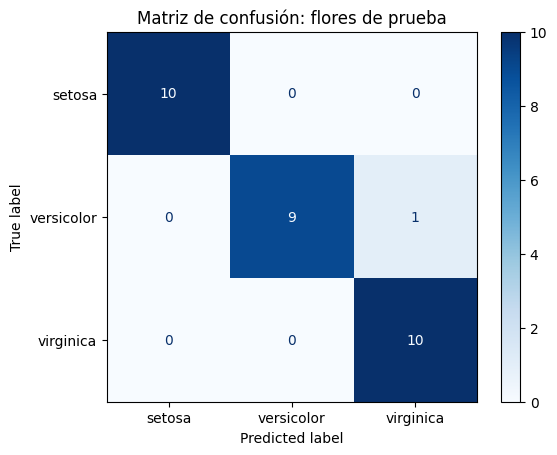

Reporte por especie:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



In [ ]:
matriz = confusion_matrix(y_test, predicciones, labels=modelo.classes_)
print(pd.DataFrame(matriz, index=modelo.classes_, columns=modelo.classes_))

ConfusionMatrixDisplay(matriz, display_labels=modelo.classes_).plot(cmap="Blues")
plt.title("Matriz de confusión: flores de prueba")
plt.show()

print("Reporte por especie:")
print(classification_report(y_test, predicciones, zero_division=0))

## 6. Comprobar manualmente la propagación hacia adelante

Aunque `scikit-learn` entrena la red, podemos repetir **su predicción usando NumPy** y los pesos aprendidos:

1. Multiplicar las entradas por los pesos y sumar sesgos.
2. Aplicar ReLU en cada capa oculta.
3. Aplicar `softmax` al final para obtener las probabilidades.

Esto **no vuelve a entrenar la red**: solo muestra cómo se genera una predicción.

In [ ]:
def softmax(valores):
    e = np.exp(valores - valores.max(axis=1, keepdims=True))
    return e / e.sum(axis=1, keepdims=True)

salida = X_test_esc[:1]  # Una flor que no se usó para entrenar.

for i, (pesos, sesgos) in enumerate(zip(modelo.coefs_, modelo.intercepts_)):
    salida = salida @ pesos + sesgos
    if i < len(modelo.coefs_) - 1:
        salida = np.maximum(0, salida)  # ReLU en capas ocultas.
    else:
        salida = softmax(salida)       # Probabilidades en la salida.

print("Probabilidades calculadas manualmente:", salida.round(4))
print("Probabilidades de scikit-learn:      ", modelo.predict_proba(X_test_esc[:1]).round(4))
print("¿Coinciden?:", np.allclose(salida, modelo.predict_proba(X_test_esc[:1])))

Probabilidades calculadas manualmente: [[9.934e-01 6.300e-03 3.000e-04]]
Probabilidades de scikit-learn:       [[9.934e-01 6.300e-03 3.000e-04]]
¿Coinciden?: True


## 7. Utilizar la red con una flor nueva

Cambia los 4 números de la siguiente celda para probar otras flores. **Orden de medidas:** largo del sépalo, ancho del sépalo, largo del pétalo y ancho del pétalo (cm).

Es muy importante pasar la nueva flor por **el mismo escalador entrenado** (solo `transform`, nunca `fit_transform`).

In [ ]:
flor_nueva = pd.DataFrame([[6.0, 2.9, 4.5, 1.5]], columns=columnas)
flor_escalada = escalador.transform(flor_nueva)

probabilidades = modelo.predict_proba(flor_escalada)[0]
especie = modelo.predict(flor_escalada)[0]

for nombre, probabilidad in zip(modelo.classes_, probabilidades):
    print(f"{nombre}: {probabilidad:.2%}")
print("Especie predicha:", especie)

setosa: 5.87%
versicolor: 81.91%
virginica: 12.21%
Especie predicha: versicolor


## 8. Conclusiones

- Utilizamos **150 flores Iris**, con **4 características** y **3 especies**.
- Dividimos en **entrenamiento (80 %)** y **prueba (20 %)**, manteniendo las clases equilibradas.
- Estandarizamos correctamente los datos sin utilizar información de prueba.
- Comparamos distintas **arquitecturas del MLP** con validación cruzada y entrenamos la seleccionada.
- Evaluamos el resultado con **accuracy**, **matriz de confusión**, **precisión**, **recall** y **F1**.
- Comprobamos que el cálculo manual del *forward pass* coincide con la predicción del modelo.

### Preguntas de repaso (con respuestas)

**1. ¿Por qué separamos entrenamiento y prueba?** Para comprobar que la red puede clasificar datos que no utilizó para aprender.

**2. ¿Qué hace ReLU?** Convierte valores negativos en cero y conserva los positivos.

**3. ¿Qué indica un 90 % de accuracy?** Que se clasificaron correctamente 90 de cada 100 datos, aproximadamente.

**4. ¿Por qué escalamos antes de entrenar?** Para que las diferencias de magnitud entre medidas no dificulten el aprendizaje.

**5. ¿Qué cambiarías para experimentar?** La arquitectura, `max_iter`, las medidas de una flor o la semilla. Si cambias la división o el modelo, los resultados pueden variar.

### Bibliografía breve
- Documentación de scikit-learn: [MLPClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.neural_network.MLPClassifier.html).
- Documentación de scikit-learn: [Iris dataset](https://scikit-learn.org/stable/datasets/toy_dataset.html#iris-dataset).
- Material original del Hands-on 3, simplificado conservando sus objetivos, análisis y ejercicios.